
# Análisis Multivariado de Varianza
## Ejemplo: Comparación de Métodos de Enseñanza
## Actividad MANOVA
### Dr. Hugo García Tecocoatzi

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_iris, load_wine, load_diabetes # Necesaria para la actividad
from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import statsmodels.api as sm
from statsmodels.formula.api import ols

%matplotlib inline

In [2]:
# Generar datos sintéticos para el ejemplo
np.random.seed(42)

# Parámetros
n_por_grupo = 30
grupos = ['A', 'B', 'C']

# Método A: Enseñanza tradicional
# Matemáticas: media 75, Lectura: media 70
mat_A = np.random.normal(75, 8, n_por_grupo)
lec_A = np.random.normal(70, 8, n_por_grupo)

# Método B: Enseñanza activa
# Matemáticas: media 82, Lectura: media 78
mat_B = np.random.normal(82, 8, n_por_grupo)
lec_B = np.random.normal(78, 8, n_por_grupo)

# Método C: Enseñanza híbrida
# Matemáticas: media 78, Lectura: media 75
mat_C = np.random.normal(78, 8, n_por_grupo)
lec_C = np.random.normal(75, 8, n_por_grupo)

# Crear DataFrame
df = pd.DataFrame({
    'Metodo': ['A']*n_por_grupo + ['B']*n_por_grupo + ['C']*n_por_grupo,
    'Matematicas': np.concatenate([mat_A, mat_B, mat_C]),
    'Lectura': np.concatenate([lec_A, lec_B, lec_C])
})

# Asegurar que las calificaciones estén en rango [0, 100]
df['Matematicas'] = np.clip(df['Matematicas'], 0, 100)
df['Lectura'] = np.clip(df['Lectura'], 0, 100)

print("Datos generados exitosamente")
print(f"Forma del dataset: {df.shape}")
print(f"Grupos: {df['Metodo'].unique()}")
df.head(10)

Datos generados exitosamente
Forma del dataset: (90, 3)
Grupos: ['A' 'B' 'C']


,Metodo,Matematicas,Lectura
0,A,78.973713,65.186347
1,A,73.893886,84.818225
2,A,80.181508,69.892022
3,A,87.184239,61.538313
4,A,73.126773,76.580359
5,A,73.126904,60.233251
6,A,87.633703,71.670909
7,A,81.139478,54.322639
8,A,71.244205,59.374512
9,A,79.340480,71.574890


In [3]:
#  Estadísticas descriptivas por grupo
print("ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: \n")

estadisticas = df.groupby('Metodo').agg({
    'Matematicas': ['mean', 'std', 'min', 'max'],
    'Lectura': ['mean', 'std', 'min', 'max']
}).round(2)

print(estadisticas)

ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: 

       Matematicas                     Lectura                    
              mean   std    min    max    mean   std    min    max
Metodo                                                            
A            73.49  7.20  59.69  87.63   69.03  7.45  54.32  84.82
B            82.10  7.94  61.04  94.52   77.84  7.27  62.65  97.71
C            77.24  8.19  65.14  95.52   77.23  7.58  65.47  96.76


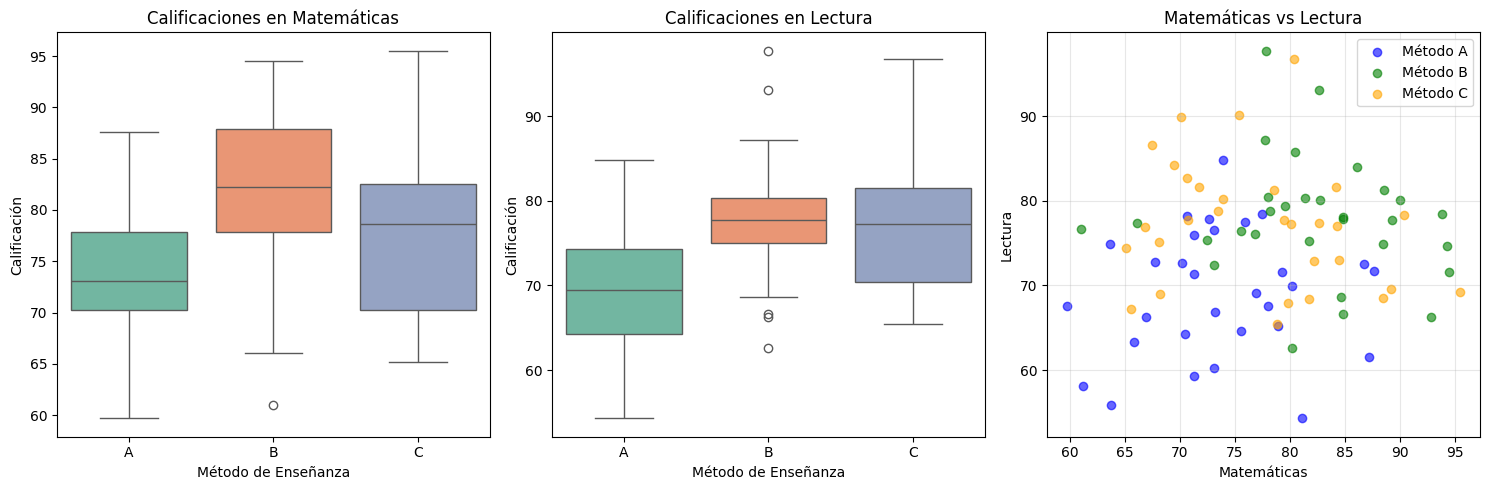

In [4]:
# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Boxplot Matemáticas
sns.boxplot(x='Metodo', y='Matematicas', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Calificaciones en Matemáticas')
axes[0].set_xlabel('Método de Enseñanza')
axes[0].set_ylabel('Calificación')

# Boxplot Lectura
sns.boxplot(x='Metodo', y='Lectura', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Calificaciones en Lectura')
axes[1].set_xlabel('Método de Enseñanza')
axes[1].set_ylabel('Calificación')

# Scatter plot Matemáticas vs Lectura
colors = {'A': 'blue', 'B': 'green', 'C': 'orange'}
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo]
    axes[2].scatter(subset['Matematicas'], subset['Lectura'],
                    alpha=0.6, label=f'Método {metodo}', color=colors[metodo])
axes[2].set_xlabel('Matemáticas')
axes[2].set_ylabel('Lectura')
axes[2].set_title('Matemáticas vs Lectura')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

             Matematicas  Lectura
Matematicas       1.0000   0.0886
Lectura           0.0886   1.0000


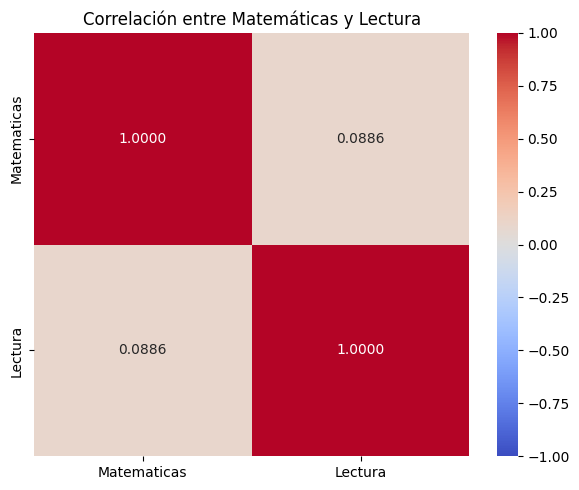

In [5]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[['Matematicas', 'Lectura']].corr().round(4))

# Visualización
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Matematicas', 'Lectura']].corr(),
            annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre Matemáticas y Lectura')
plt.tight_layout()
plt.show()

In [6]:
#  MANOVA - Prueba principal
print("MANOVA \n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Matematicas + Lectura ~ Metodo', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept         Value  Num DF  Den DF  F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda  0.0146 2.0000 86.0000 2907.3547 0.0000
         Pillai's trace  0.9854 2.0000 86.0000 2907.3547 0.0000
 Hotelling-Lawley trace 67.6129 2.0000 86.0000 2907.3547 0.0000
    Roy's greatest root 67.6129 2.0000 86.0000 2907.3547 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
           Metodo         Value  Num DF  Den DF  F Value Pr > F
---------------------------------------------------------------
            Wilks' lambda 0.6317 4.0000 172.0000 11.1040 0.0000
           Pillai's trace 0.3790 4.0000 174.0000 1

In [7]:
#  Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Metodo']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                           Value Num DF      Den DF    F Value Pr > F
Wilks' lambda           0.631651      4       172.0  11.104044    0.0
Pillai's trace          0.379027    4.0       174.0  10.171469    0.0
Hotelling-Lawley trace  0.566246      4  102.169014  12.128592    0.0
Roy's greatest root     0.534625      2          87  23.256178    0.0


In [8]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS ===\n")

# Verificar significancia de cada estadístico
for estadistico in resultados_mv.index:
    if 'p-value' in resultados_mv.columns:
        p_valor = resultados_mv.loc[estadistico, 'Pr > F']
        valor = resultados_mv.loc[estadistico, 'Value']

        if p_valor < 0.05:
            print(f"✅ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → SIGNIFICATIVO")
        else:
            print(f"❌ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → NO SIGNIFICATIVO")

print("\n Conclusión:")
print("Si todos los estadísticos son significativos (p < 0.05),")
print("existe evidencia de que los métodos de enseñanza difieren")
print("en el patrón conjunto de Matemáticas y Lectura.")

=== INTERPRETACIÓN DE RESULTADOS ===


 Conclusión:
Si todos los estadísticos son significativos (p < 0.05),
existe evidencia de que los métodos de enseñanza difieren
en el patrón conjunto de Matemáticas y Lectura.


In [9]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

# ANOVA para Matemáticas
print("ANOVA para Matemáticas:")
modelo_mat = ols('Matematicas ~ Metodo', data=df).fit()
anova_mat = sm.stats.anova_lm(modelo_mat, typ=2)
print(anova_mat.round(4))

# ANOVA para Lectura
print("\n ANOVA para Lectura:")
modelo_lec = ols('Lectura ~ Metodo', data=df).fit()
anova_lec = sm.stats.anova_lm(modelo_lec, typ=2)
print(anova_lec.round(4))

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / 2  # 2 variables dependientes

print(f"\n Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación
p_mat = anova_mat.loc['Metodo', 'PR(>F)']
p_lec = anova_lec.loc['Metodo', 'PR(>F)']

print(f"\n   Matemáticas: p = {p_mat:.4f} → {'Significativo' if p_mat < alpha_bonferroni else 'No significativo'}")
print(f"   Lectura: p = {p_lec:.4f} → {'Significativo' if p_lec < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Matemáticas:
             sum_sq    df      F  PR(>F)
Metodo    1117.7714   2.0  9.215  0.0002
Residual  5276.5085  87.0    NaN     NaN

 ANOVA para Lectura:
             sum_sq    df        F  PR(>F)
Metodo    1451.7091   2.0  13.1348     0.0
Residual  4807.8024  87.0      NaN     NaN

 Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.025

   Matemáticas: p = 0.0002 → Significativo
   Lectura: p = 0.0000 → Significativo


In [10]:
#  Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

# Tukey para Matemáticas
print("Tukey HSD para Matemáticas:")
tukey_mat = pairwise_tukeyhsd(df['Matematicas'], df['Metodo'], alpha=0.05)
print(tukey_mat)

print("\n Tukey HSD para Lectura:")
tukey_lec = pairwise_tukeyhsd(df['Lectura'], df['Metodo'], alpha=0.05)
print(tukey_lec)

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Matemáticas:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B   8.6083 0.0001  3.8136 13.403   True
     A      C   3.7455 0.1558 -1.0492 8.5402  False
     B      C  -4.8627 0.0461 -9.6574 -0.068   True
---------------------------------------------------

 Tukey HSD para Lectura:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B   8.8073    0.0  4.2305 13.3841   True
     A      C   8.1996 0.0001  3.6228 12.7764   True
     B      C  -0.6077 0.9463 -5.1845  3.9691  False
----------------------------------------------------


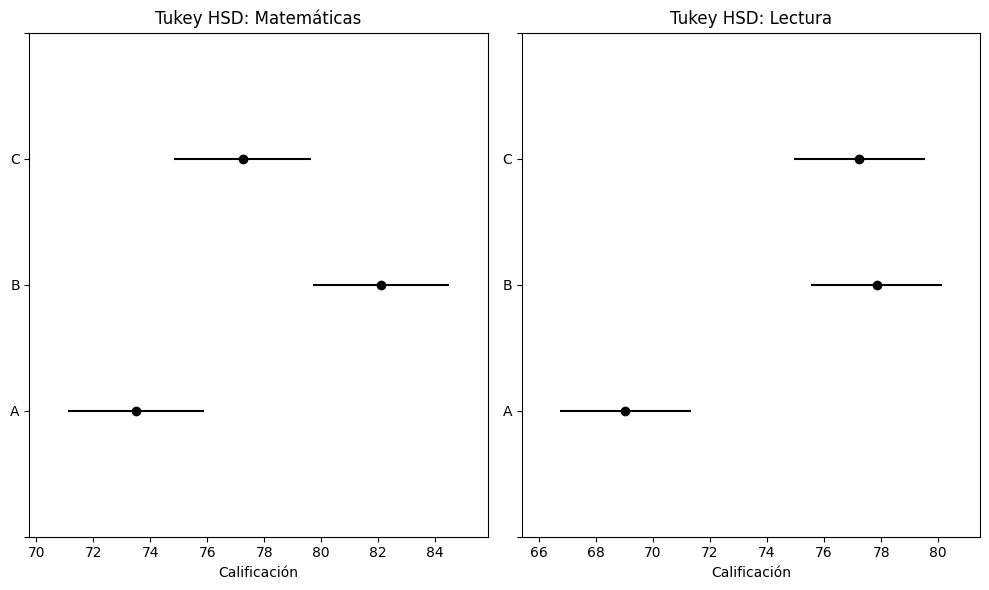

In [11]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tukey Matemáticas
tukey_mat.plot_simultaneous(ax=axes[0])
axes[0].set_title('Tukey HSD: Matemáticas')
axes[0].set_xlabel('Calificación')

# Tukey Lectura
tukey_lec.plot_simultaneous(ax=axes[1])
axes[1].set_title('Tukey HSD: Lectura')
axes[1].set_xlabel('Calificación')

plt.tight_layout()
plt.show()

In [12]:
# Verificación de supuestos - Normalidad multivariada
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

# Test de Mardia para normalidad multivariada
def mardia_test(data, alpha=0.05):
    """
    Implementación simplificada del test de Mardia
    """
    n, p = data.shape
    mean = np.mean(data, axis=0)
    centered = data - mean
    S = np.cov(data, rowvar=False)
    S_inv = np.linalg.inv(S)

    # Asimetría multivariada
    b1p = 0
    for i in range(n):
        for j in range(n):
            b1p += (centered[i] @ S_inv @ centered[j])**3
    b1p = b1p / (n**2)

    # Curtosis multivariada
    b2p = 0
    for i in range(n):
        b2p += (centered[i] @ S_inv @ centered[i])**2
    b2p = b2p / n

    # Estadísticos de prueba
    skewness_stat = n * b1p / 6
    kurtosis_stat = (b2p - p*(p+2)) / np.sqrt(8*p*(p+2)/n)

    # p-valores
    p_skewness = 1 - stats.chi2.cdf(skewness_stat, p*(p+1)*(p+2)/6)
    p_kurtosis = 2 * (1 - stats.norm.cdf(abs(kurtosis_stat)))

    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': p_skewness,
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': p_kurtosis
    }

# Aplicar test por grupo
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo][['Matematicas', 'Lectura']].values
    print(f"Método {metodo}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")

    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Método A:
  Skewness statistic: 1.9333
  Skewness p-value: 0.7480
  Kurtosis statistic: -1.1241
  Kurtosis p-value: 0.2610
  ✅ Normalidad multivariada aceptable

Método B:
  Skewness statistic: 4.0213
  Skewness p-value: 0.4031
  Kurtosis statistic: -0.2271
  Kurtosis p-value: 0.8203
  ✅ Normalidad multivariada aceptable

Método C:
  Skewness statistic: 3.1460
  Skewness p-value: 0.5337
  Kurtosis statistic: -0.9106
  Kurtosis p-value: 0.3625
  ✅ Normalidad multivariada aceptable



In [13]:
#  Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]


    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)

    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))

    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)

    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))

    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)

    # Estadístico de prueba
    chi2_stat = M * (1 - c)

    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2

    # p-valor
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)

    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[['Matematicas', 'Lectura']], df['Metodo'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 2.3240
  Chi-square: 2.2469
  df: 6.0000
  p-value: 0.8957

✅ No se rechaza H₀: Las matrices de covarianza son homogéneas


In [14]:
#  Preguntas de análisis
print(" PREGUNTAS DE ANÁLISIS:")
print("\n1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?")
print("2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?")
print("3. ¿Qué pares de grupos son significativamente diferentes?")
print("4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?")




 PREGUNTAS DE ANÁLISIS:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?
3. ¿Qué pares de grupos son significativamente diferentes?
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?


#### Respuestas
1. En este caso en específico, cualquiera de los cuatro es adecuado ya que todos arrojan un valor de p altamnete significativo. Aparte la prueba de M de Box confirmó la homogeneidad de las matrices de covarianza, no hay violaciones de supuestos que obliguen a preferiri uno más robusto como el rastri de Pillai.
2. Lectura, ya que presenta un estadístico F mayor y una mayor suma de cuadradoss entre grupos, lo que indica que el efecto de los métodos de enseñanzas se manifesta con mayor potencia en esta materia.
3. En matemáticas A vs B y B vs C, sí difieren significativamente  y en ambos casos el Método B supera al Método A. Pero en A vs C no hay diferencia significativa.
  En Lectura A vs B y A vs C sí difieren significativamente, en el primer caso el Método B supera al Método A, en el segundo caso el Método C supera al Método A. Pero en B vs C no hay diferencia significativa.
4. Sí se cumplen satisfactoriamente:
    La normalidad multivariada las pruebas de asimetría (skewness) muestran valores de p > 0.05 para los tres métodos A, B y C.
    La homogeneidad de covarianza, la prueba M de Box arrojó un valor de p de 0.8957, por lo que no se rechaza la hipótesis nula de la homocedasticidad multivariada. O sea, los resultados de MANOVA y de los ANOVAs univariado son plenamente confiables.

# Actividad MANOVA

Ahora repite todo para el siguiente dataset de load_iris

In [15]:
# Inicialización y carga de los datos base del Iris
from sklearn.datasets import load_iris
import pandas as pd

# Extracción del diccionario fuente
datos_crudos = load_iris()

# Construcción de la estructura tabular principal
df = pd.DataFrame(datos_crudos.data, columns=datos_crudos.feature_names)
df['Especie'] = datos_crudos.target_names[datos_crudos.target]

# Asignación de etiquetas descriptivas al conjunto de columnas
df.columns = [
    'Longitud_Sepalo',
    'Ancho_Sepalo',
    'Longitud_Petalo',
    'Ancho_Petalo',
    'Especie',
]

# Despliegue de validación y resumen inicial
print(f'Dimensiones del arreglo: {df.shape}')
print(f"Categorías identificadas: {df['Especie'].unique()}")
print('Conteo de registros por clase:')
print(df['Especie'].value_counts())
df.head(10)

Dimensiones del arreglo: (150, 5)
Categorías identificadas: ['setosa' 'versicolor' 'virginica']
Conteo de registros por clase:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo,Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [16]:
# ==========================================
# 2. ESTADÍSTICAS DESCRIPTIVAS POR GRUPO
# ==========================================
# Cálculo de parámetros descriptivos divididos por clase
lista_variables = [
    'Longitud_Sepalo',
    'Ancho_Sepalo',
    'Longitud_Petalo',
    'Ancho_Petalo',
]
print('RESUMEN DE MÉTRICAS POBLACIONALES:\n')

tabla_resumen = (
    df.groupby('Especie')[lista_variables]
    .agg(['mean', 'std', 'min', 'max'])
    .round(2)
)
print(tabla_resumen.T)

RESUMEN DE MÉTRICAS POBLACIONALES:

Especie               setosa  versicolor  virginica
Longitud_Sepalo mean    5.01        5.94       6.59
                std     0.35        0.52       0.64
                min     4.30        4.90       4.90
                max     5.80        7.00       7.90
Ancho_Sepalo    mean    3.43        2.77       2.97
                std     0.38        0.31       0.32
                min     2.30        2.00       2.20
                max     4.40        3.40       3.80
Longitud_Petalo mean    1.46        4.26       5.55
                std     0.17        0.47       0.55
                min     1.00        3.00       4.50
                max     1.90        5.10       6.90
Ancho_Petalo    mean    0.25        1.33       2.03
                std     0.11        0.20       0.27
                min     0.10        1.00       1.40
                max     0.60        1.80       2.50


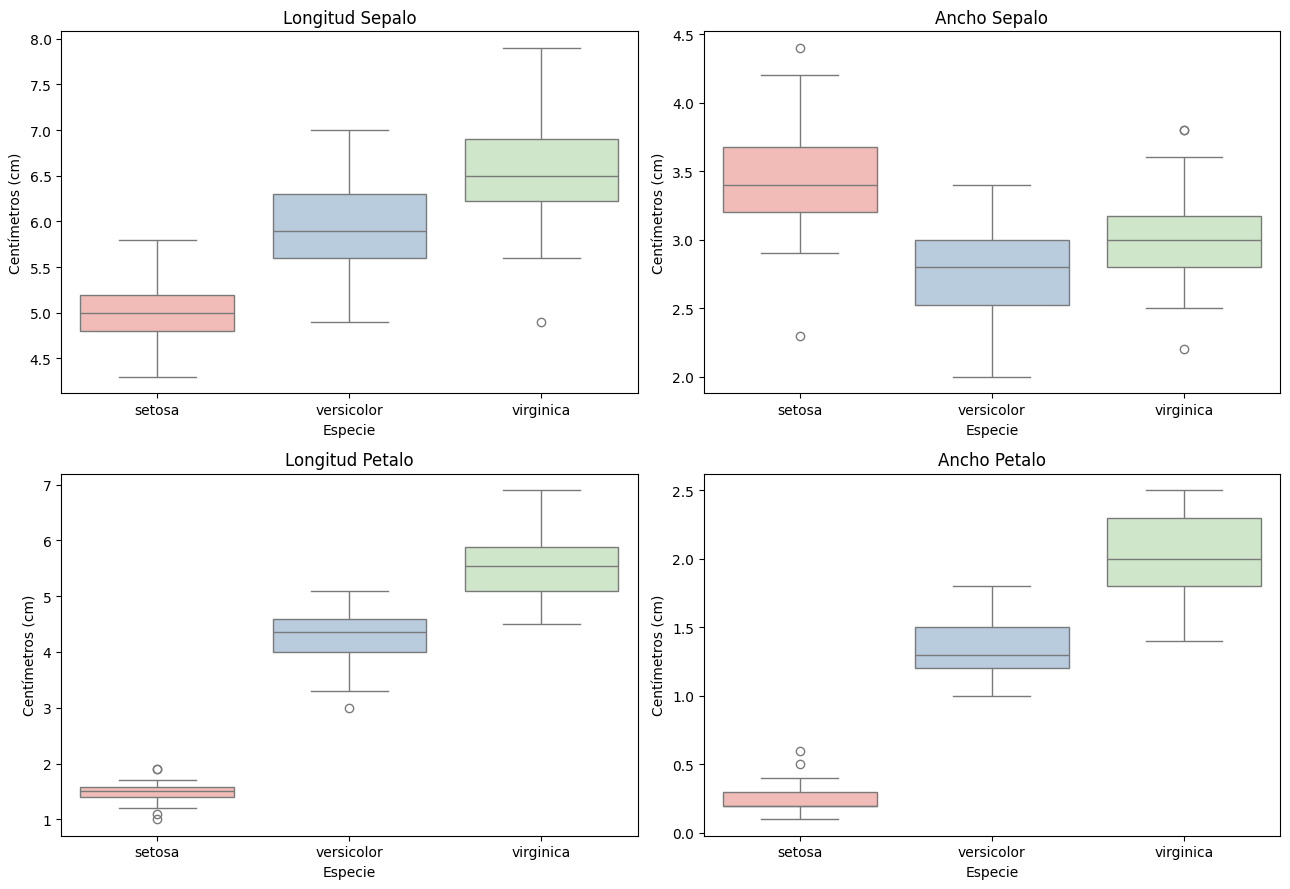

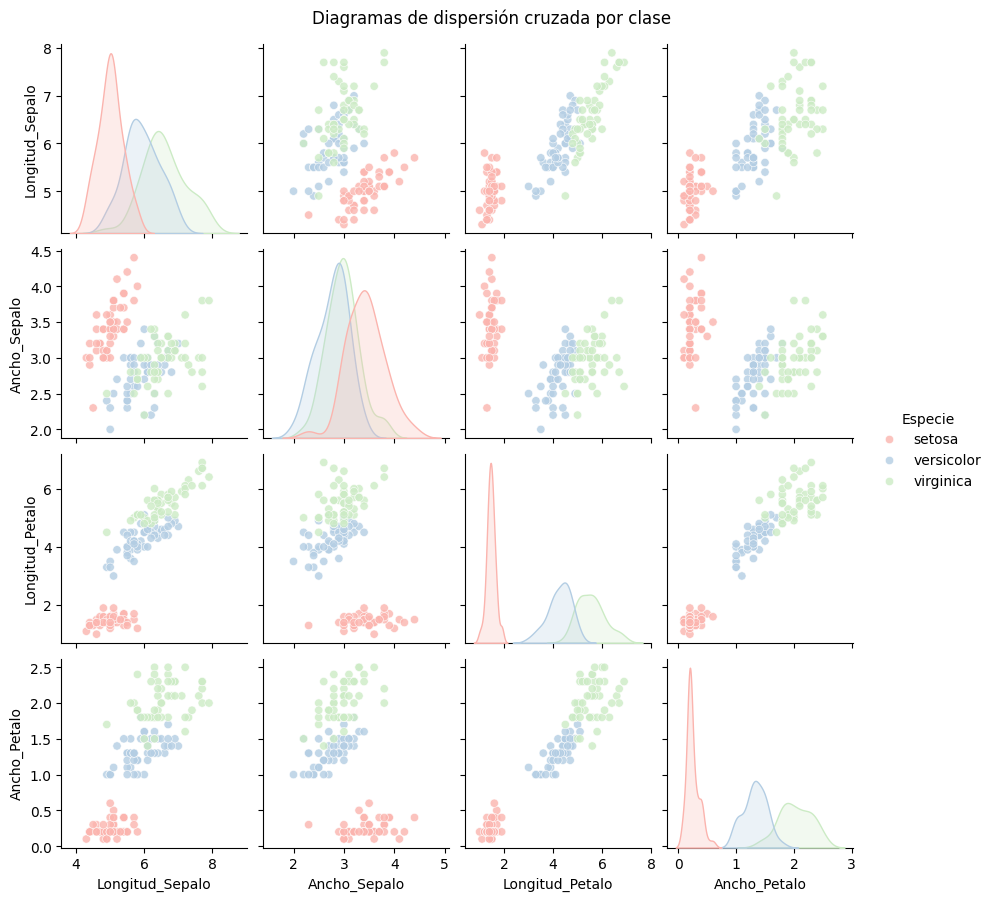

In [17]:


# VISUALIZACION
# Definición de las métricas a graficar
metricas_estudio = [
    'Longitud_Sepalo',
    'Ancho_Sepalo',
    'Longitud_Petalo',
    'Ancho_Petalo',
]

# Generación de diagramas de caja en cuadrícula de 2x2
figura, rejilla = plt.subplots(2, 2, figsize=(13, 9))
planos = rejilla.flatten()

for idx, metrica in enumerate(metricas_estudio):
  sns.boxplot(
      x='Especie', y=metrica, data=df, ax=planos[idx], palette='Pastel1'
  )
  planos[idx].set_title(metrica.replace('_', ' '))
  planos[idx].set_xlabel('Especie')
  planos[idx].set_ylabel('Centímetros (cm)')

plt.tight_layout()
plt.show()

# Matriz de dispersión cruzada por pares (Pairplot)
matriz_dispersion = sns.pairplot(
    df, hue='Especie', palette='Pastel1', height=2.2, plot_kws={'alpha': 0.8}
)
matriz_dispersion.fig.suptitle(
    'Diagramas de dispersión cruzada por clase', y=1.02
)
plt.show()

MATRIZ DE CORRELACIÓN GENERAL

                 Longitud_Sepalo  Ancho_Sepalo  Longitud_Petalo  Ancho_Petalo
Longitud_Sepalo           1.0000       -0.1176           0.8718        0.8179
Ancho_Sepalo             -0.1176        1.0000          -0.4284       -0.3661
Longitud_Petalo           0.8718       -0.4284           1.0000        0.9629
Ancho_Petalo              0.8179       -0.3661           0.9629        1.0000


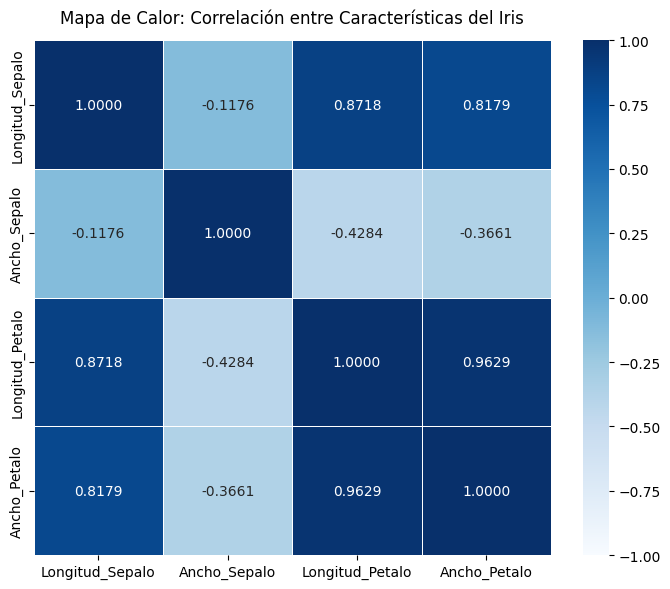

In [18]:
# Selección de las características cuantitativas para la correlación
cols_analisis = [
    'Longitud_Sepalo',
    'Ancho_Sepalo',
    'Longitud_Petalo',
    'Ancho_Petalo',
]
matriz_corr = df[cols_analisis].corr(numeric_only=True).round(4)

print('MATRIZ DE CORRELACIÓN GENERAL\n')
print(matriz_corr)

# Representación gráfica mediante mapa de calor
plt.figure(figsize=(7, 6))
sns.heatmap(
    matriz_corr,
    annot=True,
    cmap='Blues',  # Paleta de color renovada
    vmin=-1,
    vmax=1,
    fmt='.4f',
    linewidths=0.5,
)
plt.title(
    'Mapa de Calor: Correlación entre Características del Iris', pad=12
)
plt.tight_layout()
plt.show()

In [19]:
# MANOVA - Prueba principal
print('ANALISIS MULTIVARIADO DE VARIANZA (MANOVA) \n')

# Definir las variables dependientes del modelo
variables = [
    'Longitud_Sepalo',
    'Ancho_Sepalo',
    'Longitud_Petalo',
    'Ancho_Petalo',
]

# Construcción de la expresión de la fórmula
expresion_modelo = ' + '.join(variables) + ' ~ Especie'

# Ajuste del modelo multivariado general
objeto_manova = MANOVA.from_formula(expresion_modelo, data=df)
salida_mv_principal = objeto_manova.mv_test()

print(salida_mv_principal)

ANALISIS MULTIVARIADO DE VARIANZA (MANOVA) 

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Especie          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000


In [20]:
# Extracción de la tabla de resultados de los cuatro estadísticos
print("=== RESUMEN DE LOS CUATRO ESTADÍSTICOS MULTIVARIADOS ===\n")

tabla_estadisticos = objeto_manova.mv_test().results['Especie']['stat']

print("Valores de prueba calculados:")
print(tabla_estadisticos.astype(float).round(4))

=== RESUMEN DE LOS CUATRO ESTADÍSTICOS MULTIVARIADOS ===

Valores de prueba calculados:
                          Value  Num DF    Den DF    F Value  Pr > F
Wilks' lambda            0.0234     8.0  288.0000   199.1453     0.0
Pillai's trace           1.1919     8.0  290.0000    53.4665     0.0
Hotelling-Lawley trace  32.4773     8.0  203.4024   582.1970     0.0
Roy's greatest root     32.1919     4.0  145.0000  1166.9574     0.0


In [21]:
# Interpretación automática de los resultados multivariados
print('=== INTERPRETACIÓN DE LOS ESTADÍSTICOS ===\n')

for metric in tabla_estadisticos.index:
  pval_actual = float(tabla_estadisticos.loc[metric, 'Pr > F'])
  val_est = float(tabla_estadisticos.loc[metric, 'Value'])
  f_val = float(tabla_estadisticos.loc[metric, 'F Value'])

  veredicto_sig = (
      'SIGNIFICATIVO' if pval_actual < 0.05 else 'NO SIGNIFICATIVO'
  )
  print(
      f'{metric}: Estadístico = {val_est:.4f}, F = {f_val:.2f}, p ='
      f' {pval_actual:.2e} -> {veredicto_sig}'
  )

# Cálculo del tamaño del efecto multivariado basado en Wilks
lambda_wilks = float(tabla_estadisticos.loc["Wilks' lambda", 'Value'])
grados_s = min(len(variables), df['Especie'].nunique() - 1)

efecto_eta2 = 1 - lambda_wilks ** (1 / grados_s)
print(f'\nTamaño del efecto multivariado (eta cuadrado): {efecto_eta2:.4f}')

print('\nConclusión del modelo:')
print(
    'Los estadísticos demuestran significancia estadística (p < 0.05):'
    ' existen'
)
print('diferencias evidentes entre las especies según el conjunto de variables.')

=== INTERPRETACIÓN DE LOS ESTADÍSTICOS ===

Wilks' lambda: Estadístico = 0.0234, F = 199.15, p = 1.37e-112 -> SIGNIFICATIVO
Pillai's trace: Estadístico = 1.1919, F = 53.47, p = 9.74e-53 -> SIGNIFICATIVO
Hotelling-Lawley trace: Estadístico = 32.4773, F = 582.20, p = 1.08e-135 -> SIGNIFICATIVO
Roy's greatest root: Estadístico = 32.1919, F = 1166.96, p = 3.79e-109 -> SIGNIFICATIVO

Tamaño del efecto multivariado (eta cuadrado): 0.8469

Conclusión del modelo:
Los estadísticos demuestran significancia estadística (p < 0.05): existen
diferencias evidentes entre las especies según el conjunto de variables.


In [22]:
# Evaluación univariada post-hoc con corrección de Bonferroni
print('=== ANÁLISIS DE VARIANZA UNIVARIADO (POST-HOC) ===\n')

nivel_signancia = 0.05
umbral_bonferroni = nivel_signancia / len(
    variables
)  # Ajuste para las 4 características

tabla_consolidada = []

for caracteristica in variables:
  modelo_uni = ols(f'{caracteristica} ~ Especie', data=df).fit()
  tabla_anova = sm.stats.anova_lm(modelo_uni, typ=2)

  print(f'Prueba ANOVA para {caracteristica}:')
  print(tabla_anova.round(4), '\n')

  val_f = tabla_anova.loc['Especie', 'F']
  val_p = tabla_anova.loc['Especie', 'PR(>F)']
  eta_cuadrado = (
      tabla_anova.loc['Especie', 'sum_sq'] / tabla_anova['sum_sq'].sum()
  )

  tabla_consolidada.append({
      'Variable': caracteristica,
      'F': val_f,
      'p': val_p,
      'eta2': eta_cuadrado,
      'Significativo': val_p < umbral_bonferroni,
  })

print('Criterio de corrección de Bonferroni:')
print(f'   α inicial = {nivel_signancia}')
print(f'   α ajustado por comparaciones = {umbral_bonferroni}\n')

df_resumen_anova = (
    pd.DataFrame(tabla_consolidada).set_index('Variable').sort_values('eta2', ascending=False)
)
print(
    df_resumen_anova.to_string(
        formatters={
            'F': '{:.2f}'.format,
            'p': '{:.2e}'.format,
            'eta2': '{:.4f}'.format,
        }
    )
)

=== ANÁLISIS DE VARIANZA UNIVARIADO (POST-HOC) ===

Prueba ANOVA para Longitud_Sepalo:
           sum_sq     df         F  PR(>F)
Especie   63.2121    2.0  119.2645     0.0
Residual  38.9562  147.0       NaN     NaN 

Prueba ANOVA para Ancho_Sepalo:
           sum_sq     df      F  PR(>F)
Especie   11.3449    2.0  49.16     0.0
Residual  16.9620  147.0    NaN     NaN 

Prueba ANOVA para Longitud_Petalo:
            sum_sq     df          F  PR(>F)
Especie   437.1028    2.0  1180.1612     0.0
Residual   27.2226  147.0        NaN     NaN 

Prueba ANOVA para Ancho_Petalo:
           sum_sq     df         F  PR(>F)
Especie   80.4133    2.0  960.0071     0.0
Residual   6.1566  147.0       NaN     NaN 

Criterio de corrección de Bonferroni:
   α inicial = 0.05
   α ajustado por comparaciones = 0.0125

                      F        p   eta2  Significativo
Variable                                              
Longitud_Petalo 1180.16 2.86e-91 0.9414           True
Ancho_Petalo     960.01 4.17

In [23]:
# Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

# Tukey para Longitud de Sépalo
print("Tukey HSD para Longitud de Sépalo:")
tukey_sep = pairwise_tukeyhsd(
    df['Longitud_Sepalo'], df['Especie'], alpha=0.05
)
print(tukey_sep)

print("\n Tukey HSD para Longitud de Pétalo:")
tukey_pet = pairwise_tukeyhsd(
    df['Longitud_Petalo'], df['Especie'], alpha=0.05
)
print(tukey_pet)

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Longitud de Sépalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------

 Tukey HSD para Longitud de Pétalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor    2.798   0.0 2.5942 3.0018   True
    setosa  virginica     4.09   0.0 3.8862 4.2938   True
versicolor  virginica    1.292   0.0 1.0882 1.4958   True
---------------------------------------------------------


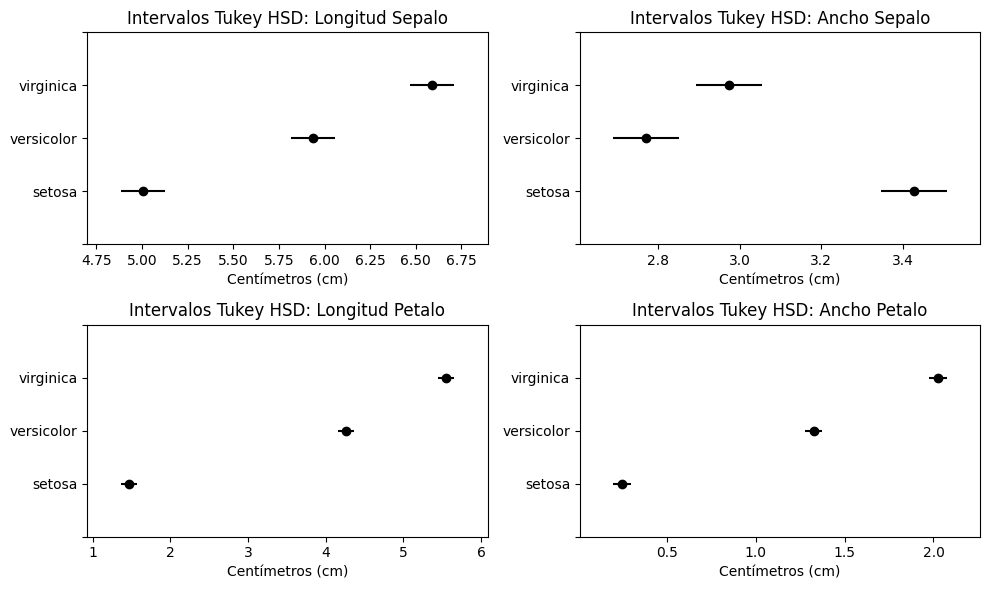

In [28]:
# Asegurar que las variables existan
if 'variables' not in globals():
  variables = [
      'Longitud_Sepalo',
      'Ancho_Sepalo',
      'Longitud_Petalo',
      'Ancho_Petalo',
  ]

# Asegurar que el diccionario de Tukey esté calculado
if 'diccionario_tukey' not in globals():
  diccionario_tukey = {
      v: pairwise_tukeyhsd(df[v], df['Especie'], alpha=0.05) for v in variables
  }

# Visualización gráfica de los intervalos simultáneos de Tukey HSD
figura_tukey, rejilla_tukey = plt.subplots(2, 2, figsize=(14, 8))
planos_tukey = rejilla_tukey.flatten()

for indice_v, variable_actual in enumerate(variables):
  diccionario_tukey[variable_actual].plot_simultaneous(
      ax=planos_tukey[indice_v]
  )
  planos_tukey[indice_v].set_title(
      f'Intervalos Tukey HSD: {variable_actual.replace("_", " ")}'
  )
  planos_tukey[indice_v].set_xlabel('Centímetros (cm)')

plt.tight_layout()
plt.show()

In [30]:
# Verificación de supuestos - Normalidad multivariada (Mardia)
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

for especie in df['Especie'].unique():
    subset = df[df['Especie'] == especie][variables].values
    print(f"Especie {especie}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")

    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

# Complemento: normalidad univariada (Shapiro-Wilk) por especie y variable
print("--- Normalidad univariada (Shapiro-Wilk, p-valores) ---\n")
shapiro = pd.DataFrame({
    especie: [stats.shapiro(df[df['Especie'] == especie][var]).pvalue for var in variables]
    for especie in df['Especie'].unique()
}, index=variables)
print(shapiro.round(4))

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Especie setosa:
  Skewness statistic: 24.1551
  Skewness p-value: 0.2357
  Kurtosis statistic: 0.7587
  Kurtosis p-value: 0.4480
  ✅ Normalidad multivariada aceptable

Especie versicolor:
  Skewness statistic: 23.7039
  Skewness p-value: 0.2556
  Kurtosis statistic: -1.0342
  Kurtosis p-value: 0.3010
  ✅ Normalidad multivariada aceptable

Especie virginica:
  Skewness statistic: 24.7257
  Skewness p-value: 0.2121
  Kurtosis statistic: -0.3384
  Kurtosis p-value: 0.7350
  ✅ Normalidad multivariada aceptable

--- Normalidad univariada (Shapiro-Wilk, p-valores) ---

                 setosa  versicolor  virginica
Longitud_Sepalo  0.4595      0.4647     0.2583
Ancho_Sepalo     0.2715      0.3380     0.1809
Longitud_Petalo  0.0548      0.1585     0.1098
Ancho_Petalo     0.0000      0.0273     0.0870


ultima parte

In [31]:
# Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

resultado_box = box_m_test(df[variables], df['Especie'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

# Complemento: homogeneidad de varianzas univariada (Levene)
print("\nTest de Levene por variable (p-valores):")
for var in variables:
    p = stats.levene(*[df[df['Especie'] == e][var] for e in df['Especie'].unique()]).pvalue
    print(f"  {var}: p = {p:.2e}")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 146.6632
  Chi-square: 140.9430
  df: 20.0000
  p-value: 0.0000

⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas
   → Considerar usar Pillai's Trace (más robusto)

Test de Levene por variable (p-valores):
  Longitud_Sepalo: p = 2.26e-03
  Ancho_Sepalo: p = 5.56e-01
  Longitud_Petalo: p = 3.13e-08
  Ancho_Petalo: p = 2.26e-08


#### Preguntas:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué? Traza de Pillia porque es el más robusto ante la violación del supuesto de homogeneidad de covarianzas.
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos? La longitud del pétalo es a¿la variable que más contribuye a las diferencias entre los grupos, de hecho el análisis discriminante (LDA) respalda este resultado al mostrar que la longitud del pétalo posee el coeficiente estandarizado más elevado en la primera función discriminante y la correlación más alta.
3. ¿Qué pares de grupos son significativamente diferentes? Practicamente todoos los pares de las cuatro variables, la menos marcada es la versicolor-virginica en el ancho del sépalo.
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene? de manera parcial:
  Normalidad: Es aceptable a nivel multivariado (Mardia), aunque Shapiro-Wilk detecta leves desviaciones univariadas en el ancho del pétalo debido a la baja cantidad de valores distintos (baja precisión de medida).
  Homogeneidad de covarianza: no se cumple
  Independecia y tamaño de muestra: se cumple con grupos iguales de n=50.
  Multicolinealidad: La longitud y el ancho del pétalo están muy correlacionados (r=0.96) , lo que genera redundancia sin volver singular la matriz


In [ ]:
#####